# Find Coincident Observations

This example demonstrates how to identify *coincident* observations, when two or more observing platforms observe the same place at (nearly) the same time, using two TAT-C analysis functions:

* `find_coincident_observations` finds the periods when observations of points (as collected by `collect_observations`) by different satellites overlap in time.
* `find_coincident_ground_track` finds the overlapping footprints of different satellites (as collected by `collect_ground_track`).

The scenario pairs a hypothetical three-satellite constellation of EUMETSAT Metop Second Generation B-series (Metop-SG-B) satellites, carrying the Ice Cloud Imager (ICI), with the first elements of NASA's proposed Fleet for the Atmosphere Linking Commercial Observations with NASA (FALCON) constellation. Coincident observations support cross-calibration and synergistic retrievals: for example, the PolSIR science team expects ICI to "serve as a reference for PolSIR", which covers the same sub-millimeter spectral range ([Bennartz and Wu, 2025](https://lps25.esa.int/lps25-presentations/presentations/1496/_1496.pdf)).

## Scenario

All parameters come from publicly available sources, listed below. Where a source gives a range or omits a value, the assumption made here is marked *assumed*.

| Element | Parameter | Value | Source |
| --- | --- | --- | --- |
| Metop-SG-B | Orbit | sun-synchronous, 832 km, 09:30 local time of descending node | [ESA, MetOp-SG facts and figures](https://www.esa.int/Applications/Observing_the_Earth/Meteorological_missions/MetOp_Second_Generation/MetOp-SG_facts_and_figures) |
| | Satellites | B1, B2, and B3 are planned to operate in sequence (2026-2048); here, *assumed* to fly together, evenly phased in one orbital plane | [WMO OSCAR](https://space.oscar.wmo.int/instruments/view/ici) |
| MWI and ICI | Scan | conical, forward view over +/-65 deg of azimuth (about 1700 km swath), yaw-steered platform | [MWI-ICI Science Plan (EUMETSAT, 2017)](https://user.eumetsat.int/s3/eup-strapi-media/pdf_science_epssg_mwi_ici_plan_6c6e1a4b97.pdf), Sec. 4 |
| | Cone (offset) angle | MWI 44.82 deg, ICI 44.6 deg (53 deg incidence) | MWI-ICI Science Plan, Sec. 4.1-4.2 |
| FALCON | Elements | begins with the INCUS and PolSIR missions; later elements (FALCON Lidar, FALCON Radar, STRIVE, and a commercial radiometer) are omitted, as FALCON's orbital architecture is still under investigation | [NASA RFI NNH26ZDA007L (2026)](https://go.nasa.gov/atmrorfi), Sec. 1 |
| PolSIR | Orbit | two satellites, 51.2 deg inclination, 550 km, 90 deg apart in right ascension of the ascending node | [Bennartz and Wu (2025)](https://lps25.esa.int/lps25-presentations/presentations/1496/_1496.pdf) |
| | Radiometer | cross-track scanning, 325 and 683 GHz; scan range *assumed* +/-45 deg | [eoPortal](https://www.eoportal.org/satellite-missions/polsir) |
| INCUS | Orbit | three satellites 30 s and 90 s apart; 38 deg inclination; altitude 450-550 km (*assumed* 500 km) | [CSU INCUS mission](https://incus.colostate.edu/mission/mission-instruments), [van den Heever et al. (2025)](https://vandenheever.atmos.colostate.edu/vdhpage/presentation_files/Dolan_AGU_Fall_M_2025.pdf) |
| | Instruments | Ka-band radar on each satellite (10 km swath); cross-track radiometer on the middle satellite (<500 km swath, *assumed* 500 km) | CSU INCUS mission, van den Heever et al. (2025) |

The analysis starts on 1 July 2029, after FALCON's planned launches. The relative phasing of the orbits (FALCON's right ascensions of the ascending node and the Metop-SG-B satellites' positions in their plane) is *assumed*; it changes when and where coincidences occur, but less so how often over a week, as the non-sun-synchronous FALCON orbits precess relative to Metop-SG-B by several degrees per day.

In [1]:
from datetime import datetime, time, timedelta, timezone

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tatc.schemas import (
    CircularOrbit,
    ConicalInstrument,
    PointedInstrument,
    Satellite,
    SunSynchronousOrbit,
    WalkerConstellation,
)
from tatc.utils import (
    ViewGeometry,
    compute_along_track_field_of_view,
    swath_width_to_field_of_regard,
)

START = datetime(2029, 7, 1, tzinfo=timezone.utc)
END = START + timedelta(days=7)
TIME_STEP = 60  # seconds between ground track samples
METOP_ALTITUDE = 832e3
POLSIR_ALTITUDE = 550e3
INCUS_ALTITUDE = 500e3

# colors (in fixed order) for the FALCON instruments
COLORS = {"PolSIR": "#2a78d6", "INCUS radiometer": "#eb6834", "INCUS radar": "#1baf7a"}
GRAY = "#8a8985"

## Choosing MWI or ICI

Metop-SG-B carries two conical imagers with the same scan sector, +/-65 deg of azimuth ahead of the satellite. They differ in their cone angle, the angle of the scanned cone from nadir. Each is modeled as a `ConicalInstrument` whose along-track field of view is the distance the satellite advances in one ground track time step (see `compute_along_track_field_of_view`), so that consecutive footprints tile its swath.

In [2]:
def conical_imager(name, cone_angle):
    return ConicalInstrument(
        name=name,
        cone_angle=cone_angle,
        scan_center_azimuth=0,
        scan_half_width=65,
        along_track_field_of_view=compute_along_track_field_of_view(
            METOP_ALTITUDE, TIME_STEP, 98.7
        ),
    )


mwi = conical_imager("MWI", 44.82)
ici = conical_imager("ICI", 44.6)
pd.DataFrame(
    {
        "cone angle (deg)": [i.cone_angle for i in (mwi, ici)],
        "swath width (km)": [i.get_swath_width(METOP_ALTITUDE) / 1e3 for i in (mwi, ici)],
    },
    index=["MWI", "ICI"],
).round(1)

,cone angle (deg),swath width (km)
MWI,44.8,1615.2
ICI,44.6,1600.7


ICI's smaller cone angle gives it the narrower swath, so its coverage is the more constrained of the two (it also samples along track more coarsely, about 15 km per scan rather than MWI's 10 km, according to [WMO OSCAR](https://space.oscar.wmo.int/instruments/view/ici)). The rest of this example uses ICI, whose sub-millimeter channels also overlap PolSIR's.

The three Metop-SG-B satellites share one sun-synchronous orbital plane, evenly phased by a Walker constellation with one plane.

In [3]:
metop = WalkerConstellation(
    name="Metop-SG-B",
    orbit=SunSynchronousOrbit(
        mean_altitude=METOP_ALTITUDE,
        equator_crossing_time=time(9, 30),
        equator_crossing_ascending=False,
        epoch=START,
    ),
    number_satellites=3,
    number_planes=1,
    instruments=[ici],
).generate_members()
[satellite.name for satellite in metop]

['Metop-SG-B 1', 'Metop-SG-B 2', 'Metop-SG-B 3']

## FALCON Constellation

The PolSIR and INCUS radiometers scan across track; INCUS's radars view a narrow strip at nadir. Each is modeled as a nadir-pointed `PointedInstrument` with a scan view geometry, a cross-track field of view sized to its swath, and an along-track field of view for the ground track time step. The INCUS satellites share an orbit, with the second and third satellites trailing the first by 30 s and 120 s.

In [4]:
def cross_track_instrument(name, altitude, inclination, cross_track_field_of_view):
    return PointedInstrument(
        name=name,
        field_of_regard=cross_track_field_of_view,
        cross_track_field_of_view=cross_track_field_of_view,
        along_track_field_of_view=compute_along_track_field_of_view(
            altitude, TIME_STEP, inclination
        ),
        is_rectangular=True,
        view_geometry=ViewGeometry.SCAN,
    )


polsir_radiometer = cross_track_instrument("PolSIR", POLSIR_ALTITUDE, 51.2, 90)
polsir = [
    Satellite(
        name=f"PolSIR-{i + 1}",
        orbit=CircularOrbit(
            mean_altitude=POLSIR_ALTITUDE,
            inclination=51.2,
            right_ascension_ascending_node=raan,
            epoch=START,
        ),
        instruments=[polsir_radiometer],
    )
    for i, raan in enumerate([0, 90])
]

incus_radar = cross_track_instrument(
    "INCUS radar", INCUS_ALTITUDE, 38, swath_width_to_field_of_regard(INCUS_ALTITUDE, 10e3)
)
incus_radiometer = cross_track_instrument(
    "INCUS radiometer", INCUS_ALTITUDE, 38, swath_width_to_field_of_regard(INCUS_ALTITUDE, 500e3)
)
incus_orbit = CircularOrbit(
    mean_altitude=INCUS_ALTITUDE, inclination=38, right_ascension_ascending_node=45, epoch=START
)
incus_rate = 360 / incus_orbit.get_orbit_period().total_seconds()  # deg/s
incus = [
    Satellite(
        name=f"INCUS-{name}",
        orbit=incus_orbit.model_copy(update={"true_anomaly": (-incus_rate * delay) % 360}),
        instruments=[incus_radar, incus_radiometer] if name == "B" else [incus_radar],
    )
    for name, delay in [("A", 0), ("B", 30), ("C", 120)]
]

satellites = metop + polsir + incus
mission = {s.name: "Metop-SG-B" if s in metop else s.name.split("-")[0] for s in satellites}
constellation = {s.name: "Metop-SG-B" if s in metop else "FALCON" for s in satellites}
pd.DataFrame(
    [
        {
            "satellite": s.name,
            "mission": mission[s.name],
            "constellation": constellation[s.name],
            "instruments": ", ".join(
                f"{i.name} ({i.get_swath_width(s.orbit.mean_altitude) / 1e3:.0f} km)"
                for i in s.instruments
            ),
        }
        for s in satellites
    ]
)

,satellite,mission,constellation,instruments
0,Metop-SG-B 1,Metop-SG-B,Metop-SG-B,ICI (1601 km)
1,Metop-SG-B 2,Metop-SG-B,Metop-SG-B,ICI (1601 km)
2,Metop-SG-B 3,Metop-SG-B,Metop-SG-B,ICI (1601 km)
3,PolSIR-1,PolSIR,FALCON,PolSIR (1154 km)
4,PolSIR-2,PolSIR,FALCON,PolSIR (1154 km)
5,INCUS-A,INCUS,FALCON,INCUS radar (10 km)
6,INCUS-B,INCUS,FALCON,"INCUS radar (10 km), INCUS radiometer (500 km)"
7,INCUS-C,INCUS,FALCON,INCUS radar (10 km)


## Coincident Observations of Points

`collect_observations` collects the observations of points of interest, here a Fibonacci lattice of points about 750 km apart between 60 deg south and 60 deg north (the latitudes FALCON observes), by every instrument (`instrument_index=None`) over one week.

In [5]:
from tatc.analysis import collect_observations
from tatc.generation import generate_points_fibonacci_lattice

points = generate_points_fibonacci_lattice(750e3)
points = points[points.geometry.y.abs() <= 60].reset_index(drop=True)
observations = collect_observations(
    list(points.geometry), satellites, START, END, instrument_index=None
)
observations.groupby(["satellite", "instrument"]).size().rename("observations").to_frame()

observations
satellite    instrument                    
INCUS-A      INCUS radar                 93
INCUS-B      INCUS radar                101
             INCUS radiometer          4557
INCUS-C      INCUS radar                 95
Metop-SG-B 1 ICI                       9937
Metop-SG-B 2 ICI                       9941
Metop-SG-B 3 ICI                       9948
PolSIR-1     PolSIR                   10581
PolSIR-2     PolSIR                   10568

`find_coincident_observations` treats each satellite as a distinct platform, so observations by two Metop-SG-B satellites would coincide with each other. To find only coincidences *between* the constellations, the `satellite` column is relabeled with the constellation before the call, making each constellation one platform.

Observations coincide if the gap between their periods is at most `max_time_difference`, here 15 minutes. Each coincident period is the time that observations by both constellations, each widened by half of `max_time_difference`, overlap; `satellite` and `instrument` list the contributors in order of their start.

In [6]:
from tatc.analysis import find_coincident_observations

by_constellation = observations.assign(satellite=observations.satellite.map(constellation))
coincident = find_coincident_observations(
    by_constellation, max_time_difference=timedelta(minutes=15)
)
display(coincident.head())

,target_hash,geometry,satellite,instrument,start,epoch,end
0,3ced23b233272b4b,POINT Z (144.31672 15.55517 0),"FALCON, Metop-SG-B","INCUS radiometer, ICI",2029-07-01 00:00:11.254653012+00:00,2029-07-01 00:07:44.582561277+00:00,2029-07-01 00:15:17.910469543+00:00
1,c4f2cff22543b4af,POINT Z (149.05274 19.08616 0),"Metop-SG-B, FALCON","ICI, INCUS radiometer",2029-07-01 00:00:39.953887246+00:00,2029-07-01 00:08:46.280635710+00:00,2029-07-01 00:16:52.607384174+00:00
2,62c3f641ea5270a7,POINT Z (139.58069 12.08383 0),"FALCON, FALCON, Metop-SG-B","INCUS radiometer, INCUS radar, ICI",2029-07-01 00:01:22.792409721+00:00,2029-07-01 00:08:01.967124430+00:00,2029-07-01 00:14:41.141839139+00:00
3,b3750db3a0eb9b9b,POINT Z (134.84467 8.65701 0),"FALCON, Metop-SG-B","INCUS radiometer, ICI",2029-07-01 00:02:47.759772846+00:00,2029-07-01 00:07:26.834445955+00:00,2029-07-01 00:12:05.909119064+00:00
4,c6abca90563d73b7,POINT Z (142.08067 50.03491 0),"Metop-SG-B, FALCON","ICI, PolSIR",2029-07-01 00:11:01.180069730+00:00,2029-07-01 00:12:56.219171430+00:00,2029-07-01 00:14:51.258273131+00:00


The number of coincidences depends strongly on the maximum time difference. Observations of a point by satellites in different orbits rarely overlap exactly; most coincidences are near-simultaneous passes separated by a few minutes.

In [7]:
rows = []
for minutes in [0, 5, 15, 30, 60]:
    result = find_coincident_observations(
        by_constellation, max_time_difference=timedelta(minutes=minutes)
    )
    rows.append(
        {
            "max time difference (min)": minutes,
            "coincidences": len(result),
            "points with a coincidence (%)": 100 * result.target_hash.nunique() / len(points),
        }
    )
pd.DataFrame(rows).set_index("max time difference (min)").round(1)

,coincidences,points with a coincidence (%)
max time difference (min),,
0,965,61.7
5,1816,72.7
15,3576,83.8
30,4502,92.7
60,6873,96.1


Each coincidence lists the instruments that contributed to it. Most pair ICI with PolSIR, whose two satellites observe more often than the single INCUS radiometer; the INCUS radars, with their 10 km swath, rarely pass over a point of the lattice.

In [8]:
def falcon_instruments(instruments):
    return ", ".join(sorted(set(instruments.split(", ")) - {"ICI"}))


coincident.instrument.map(falcon_instruments).value_counts().rename_axis(
    "FALCON instruments"
).rename("coincidences").to_frame()

,coincidences
FALCON instruments,
PolSIR,3040
INCUS radiometer,517
"INCUS radar, INCUS radiometer",17
"INCUS radiometer, PolSIR",2


Coincident observations have the columns of collected observations, so `aggregate_observations` and `reduce_observations` compute their statistics: here, the number of coincidences (`samples`) at each point over the week and the mean time between them (`revisit`). Coincidences are most frequent near 50 to 60 deg north and south, where PolSIR's ground tracks turn and are densest, and points without any coincidence in the week lie mostly at lower latitudes.

,samples,revisit
count,839.000000,723
mean,4.262217,1 days 04:45:39.341271966
std,2.423117,0 days 22:00:08.682351193
min,1.000000,0 days 00:09:02.321197530
25%,2.000000,0 days 17:44:03.930860342
50%,4.000000,0 days 23:34:31.711996125
75%,6.000000,1 days 07:11:52.029683234
max,11.000000,6 days 13:00:15.277743627


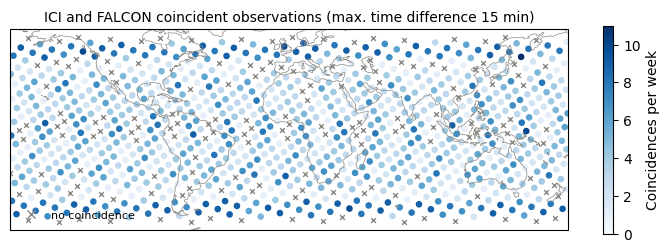

In [9]:
from tatc.analysis import aggregate_observations, reduce_observations

reduced = reduce_observations(aggregate_observations(coincident))
display(reduced[["samples", "revisit"]].describe())

fig, ax = plt.subplots(figsize=(9, 4.5), subplot_kw={"projection": ccrs.PlateCarree()})
points[~points.point_id.isin(reduced.target_hash)].plot(
    ax=ax, color=GRAY, markersize=12, marker="x", linewidth=1, label="no coincidence"
)
reduced.plot(
    ax=ax,
    column="samples",
    cmap="Blues",
    vmin=0,
    markersize=14,
    legend=True,
    legend_kwds={"label": "Coincidences per week", "shrink": 0.6},
)
ax.coastlines(color=GRAY, linewidth=0.5)
ax.set_extent([-180, 180, -65, 65], crs=ccrs.PlateCarree())
ax.legend(
    handles=[plt.Line2D([], [], marker="x", color=GRAY, linestyle="none")],
    labels=["no coincidence"],
    loc="lower left",
    fontsize=8,
    frameon=False,
)
ax.set_title("ICI and FALCON coincident observations (max. time difference 15 min)", fontsize=10)
plt.show()

Coincidences among more than two platforms use `min_platforms`. Relabeling the `satellite` column with each mission (Metop-SG-B, PolSIR, or INCUS) finds the points observed by all three missions within the maximum time difference, which are rare. (A mission appears once per instrument that contributes.)

In [10]:
by_mission = observations.assign(satellite=observations.satellite.map(mission))
find_coincident_observations(
    by_mission, min_platforms=3, max_time_difference=timedelta(minutes=15)
)

,target_hash,geometry,satellite,instrument,start,epoch,end
0,678670b6a603cfbd,POINT Z (125.79967 -38.27067 0),"Metop-SG-B, INCUS, PolSIR","ICI, INCUS radiometer, PolSIR",2029-07-07 14:20:29.222356576+00:00,2029-07-07 14:21:54.033398351+00:00,2029-07-07 14:23:18.844440127+00:00
1,dba788a000f429d1,POINT Z (172.73285 38.39704 0),"Metop-SG-B, INCUS, PolSIR","ICI, INCUS radiometer, PolSIR",2029-07-07 23:05:31.588398224+00:00,2029-07-07 23:06:35.859609001+00:00,2029-07-07 23:07:40.130819778+00:00


## Coincident Ground Tracks

Points sample coincidences at discrete locations. Ground tracks instead give the *areas* observed in common. `collect_ground_track` collects every instrument's footprint at each time step (here, every minute for the week); with the along-track fields of view chosen above, consecutive footprints tile each swath.

`find_coincident_ground_track` pairs the footprints of different satellites whose times differ by at most `max_time_difference` and which overlap, recording the columns of both footprints (suffixed `_1` and `_2`, with `time_1` no later than `time_2`) and their overlap as the geometry. As before, the `satellite` column is relabeled with the constellation (keeping each satellite's name in a `member` column), so that only pairs between the constellations are found.

In [11]:
from tatc.analysis import collect_ground_track, find_coincident_ground_track

times = pd.date_range(START, END, freq=f"{TIME_STEP}s", inclusive="left")
ground_track = collect_ground_track(satellites, list(times), instrument_index=None)
pairs = find_coincident_ground_track(
    ground_track.assign(
        member=ground_track.satellite, satellite=ground_track.satellite.map(constellation)
    ),
    max_time_difference=timedelta(minutes=15),
)
display(pairs.head())

,time_1,satellite_1,instrument_1,valid_obs_1,member_1,time_2,satellite_2,instrument_2,valid_obs_2,member_2,time_difference,geometry
0,2029-07-01 00:02:00+00:00,FALCON,INCUS radiometer,True,INCUS-B,2029-07-01 00:15:00+00:00,Metop-SG-B,ICI,True,Metop-SG-B 2,0 days 00:13:00,"POLYGON Z ((132.11799 3.50472 0, 132.60076 3.0..."
1,2029-07-01 00:02:00+00:00,FALCON,INCUS radar,True,INCUS-A,2029-07-01 00:15:00+00:00,Metop-SG-B,ICI,True,Metop-SG-B 2,0 days 00:13:00,"POLYGON Z ((132.47031 5.86551 0, 132.47747 5.8..."
2,2029-07-01 00:02:00+00:00,FALCON,INCUS radiometer,True,INCUS-B,2029-07-01 00:16:00+00:00,Metop-SG-B,ICI,True,Metop-SG-B 2,0 days 00:14:00,"POLYGON Z ((131.7861 2.42426 0, 131.42029 2.11..."
3,2029-07-01 00:03:00+00:00,FALCON,INCUS radar,True,INCUS-A,2029-07-01 00:13:00+00:00,Metop-SG-B,ICI,True,Metop-SG-B 2,0 days 00:10:00,"POLYGON Z ((134.54656 7.60036 0, 134.89614 7.8..."
4,2029-07-01 00:03:00+00:00,FALCON,INCUS radar,True,INCUS-B,2029-07-01 00:14:00+00:00,Metop-SG-B,ICI,True,Metop-SG-B 2,0 days 00:11:00,"POLYGON Z ((132.68877 6.15494 0, 133.02192 6.4..."


Each pair's FALCON instrument is the one not on Metop-SG-B. Dissolving the overlaps of each instrument gives the area observed in common with ICI over the week (computed in an equal-area projection), and the time differences (multiples of the one-minute time step) show how close in time the coincidences are.

In [12]:
metop_first = pairs.satellite_1 == "Metop-SG-B"
pairs["falcon_instrument"] = pairs.instrument_2.where(metop_first, pairs.instrument_1)
pairs["metop_first"] = metop_first
areas = pairs.dissolve(by="falcon_instrument")
pd.DataFrame(
    {
        "pairs": pairs.groupby("falcon_instrument").size(),
        "ICI first (%)": 100 * pairs.groupby("falcon_instrument").metop_first.mean(),
        "median time difference (min)": pairs.groupby("falcon_instrument").time_difference.median().dt.total_seconds() / 60,
        "coincident area (million km2)": areas.to_crs("EPSG:6933").area / 1e12,
    }
).reindex(COLORS).round(1)

,pairs,ICI first (%),median time difference (min),coincident area (million km2)
falcon_instrument,,,,
PolSIR,13202,52.0,8.0,327.4
INCUS radiometer,3339,51.1,8.0,95.0
INCUS radar,5500,50.8,8.0,8.8


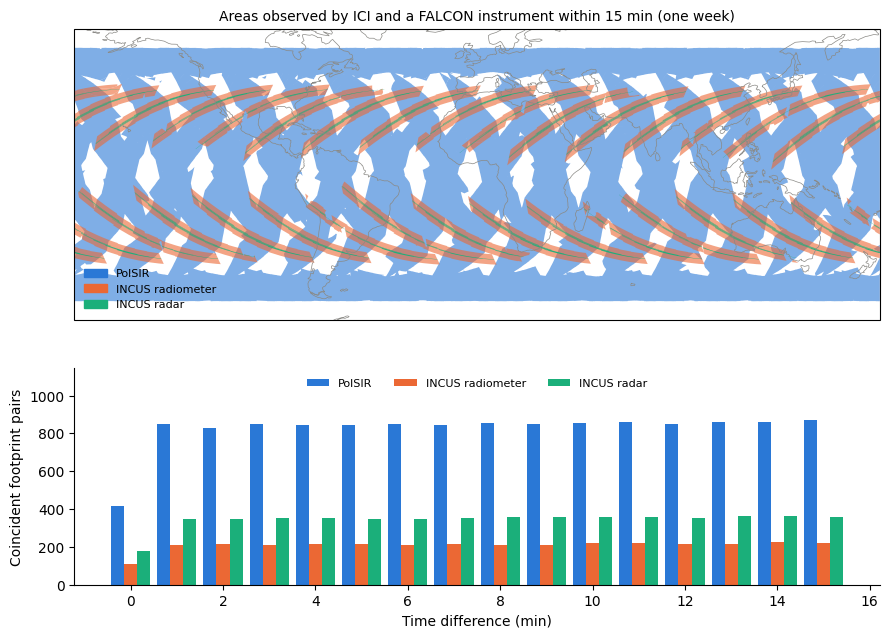

In [13]:
fig, (ax, hist) = plt.subplots(
    2,
    1,
    figsize=(9, 7),
    height_ratios=[2, 1],
    subplot_kw={},
)
ax.remove()
ax = fig.add_subplot(2, 1, 1, projection=ccrs.PlateCarree())
for instrument, color in COLORS.items():
    if instrument in areas.index:
        areas.loc[[instrument]].plot(
            ax=ax, color=color, alpha=0.6 if instrument != "INCUS radar" else 1, edgecolor="none"
        )
ax.coastlines(color=GRAY, linewidth=0.5)
ax.set_extent([-180, 180, -65, 65], crs=ccrs.PlateCarree())
ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()],
    labels=list(COLORS),
    loc="lower left",
    fontsize=8,
    frameon=False,
)
ax.set_title("Areas observed by ICI and a FALCON instrument within 15 min (one week)", fontsize=10)

bins = np.arange(-0.5, 16)
hist.hist(
    [pairs[pairs.falcon_instrument == i].time_difference.dt.total_seconds() / 60 for i in COLORS],
    bins=bins,
    color=list(COLORS.values()),
    label=list(COLORS),
    rwidth=0.85,
)
hist.set(xlabel="Time difference (min)", ylabel="Coincident footprint pairs")
hist.spines[["top", "right"]].set_visible(False)
hist.set_ylim(top=1.25 * hist.get_ylim()[1])
hist.legend(frameon=False, fontsize=8, ncol=3, loc="upper center")
fig.tight_layout()
plt.show()

## Summary

* ICI's narrower swath (about 1600 km at 832 km altitude) makes it the more constrained of Metop-SG-B's two conical imagers.
* With a 15 minute window, ICI on three Metop-SG-B satellites and the FALCON instruments observe most of the points between 60 deg south and 60 deg north in common at least once a week, mostly with PolSIR.
* Coincidences with all three missions at once are rare.
* Coincident footprints are spread evenly over time differences up to the maximum, so the coincident area grows with the window.
* The INCUS radars' narrow swath makes their coincidences with ICI strips along their ground tracks, which points spaced hundreds of kilometers apart rarely sample but ground tracks capture.

These results depend on assumptions about the orbits' relative phasing and the instruments' scan ranges (see Scenario), which can be updated as the missions' designs are published.